# QNN — Ising phase classification

AngleEmbedding + BasicEntanglerLayers + Torch head (2 clases).


## Librerias


In [1]:
import json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import pennylane as qml
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


## Data


In [2]:
# Load PennyLane qspin Ising (4 qubits) and build phase labels
# Features = ground-state amplitudes (Re||Im). Labels from physics: y=(h > |J|).
# IMPORTANT: h is NOT included as a feature (would leak the label).

ISING_LAYOUTS = [
    {"periodicity": "open", "lattice": "chain", "layout": "1x4"},
    {"periodicity": "closed", "lattice": "chain", "layout": "1x4"},
]


def fix_global_phase(states: np.ndarray) -> np.ndarray:
    """Remove global phase so the first amplitude is real and non-negative when possible."""
    ref = states[:, 0].copy()
    tiny = np.abs(ref) < 1e-12
    if np.any(tiny):
        idx = np.argmax(np.abs(states[tiny]), axis=1)
        ref[tiny] = states[tiny, idx]
        ref[np.abs(ref) < 1e-12] = 1.0
    return states * np.exp(-1j * np.angle(ref))[:, None]


def load_ising_phase_dataset(layouts=ISING_LAYOUTS):
    Xs, ys, meta_h = [], [], []
    for cfg in layouts:
        ds = qml.data.load(
            "qspin",
            sysname="Ising",
            periodicity=cfg["periodicity"],
            lattice=cfg["lattice"],
            layout=cfg["layout"],
        )[0]
        gs = np.asarray(ds.ground_states, dtype=np.complex128)
        gs = fix_global_phase(gs)
        X = np.concatenate([gs.real, gs.imag], axis=1)  # (n, 32) for 4 qubits
        h = np.asarray(ds.parameters["h"], dtype=float)
        J = abs(float(ds.parameters["J"]))
        y = (h > J).astype(int)  # 0 ordered (low h), 1 disordered (high h)
        Xs.append(X)
        ys.append(y)
        meta_h.append(h)
        print(
            f"Loaded Ising {cfg['periodicity']} {cfg['lattice']} {cfg['layout']}: "
            f"X={X.shape}, classes={np.unique(y, return_counts=True)}, hc=|J|={J}"
        )
    X = np.vstack(Xs)
    y = np.concatenate(ys)
    h_all = np.concatenate(meta_h)
    return X, y, h_all


print("Loading Ising phase-classification dataset from PennyLane qspin...")
X_all, y_all, h_all = load_ising_phase_dataset()
print(f"Combined: n={len(X_all)}, features={X_all.shape[1]}, classes={np.unique(y_all, return_counts=True)}")


Loading Ising phase-classification dataset from PennyLane qspin...
Loaded Ising open chain 1x4: X=(100, 32), classes=(array([0, 1]), array([34, 66])), hc=|J|=1.0
Loaded Ising closed chain 1x4: X=(100, 32), classes=(array([0, 1]), array([25, 75])), hc=|J|=1.0
Combined: n=200, features=32, classes=(array([0, 1]), array([ 59, 141]))


## Data Preparation


In [3]:
torch.manual_seed(123); np.random.seed(123)
n_qubits = 4
n_classes = 2
X = X_all; y = y_all
X_train_raw, X_test_raw, y_train_np, y_test_np, h_train, h_test = train_test_split(
    X, y, h_all, test_size=0.4, random_state=123, stratify=y
)
pca = PCA(n_components=n_qubits, random_state=123)
X_train_pca = pca.fit_transform(X_train_raw)
X_test_pca = pca.transform(X_test_raw)
print(f"PCA explained variance ratio sum: {pca.explained_variance_ratio_.sum():.4f}")
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_scaled = scaler.fit_transform(X_train_pca)
X_test_scaled = np.clip(scaler.transform(X_test_pca), 0, np.pi)
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)
y_test = torch.tensor(y_test_np, dtype=torch.long)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
n_features = n_qubits
print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")
print(f"Final shapes -> Train: {tuple(X_train.shape)}, Test: {tuple(X_test.shape)}")


PCA explained variance ratio sum: 0.9993
Custom Dataset Loaded: Train=120, Test=80
Final shapes -> Train: (120, 4), Test: (80, 4)


## Quantum Neural Network


In [4]:
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (6, n_qubits)}

class QNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.post = nn.Linear(n_qubits, n_classes)
    def forward(self, x):
        return self.post(self.qlayer(x))


## Entrenamiento QNN


In [5]:
def train_model(model, loader, epochs=30, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = []
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0.0
        for bx, by in loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward(); optimizer.step()
            epoch_loss += loss.item()
        avg = epoch_loss / len(loader)
        history.append(avg)
        print(f"Epoch {epoch+1:2d} | Loss: {avg:.4f}")
    return history

qnn_model = QNN()
start = time.time()
qnn_history = train_model(qnn_model, train_loader, epochs=30, lr=0.01)
qnn_time = time.time() - start
print(f"QNN training time: {qnn_time:.2f}s")


Epoch  1 | Loss: 0.6636
Epoch  2 | Loss: 0.6278
Epoch  3 | Loss: 0.5982
Epoch  4 | Loss: 0.5672
Epoch  5 | Loss: 0.5501
Epoch  6 | Loss: 0.5302
Epoch  7 | Loss: 0.4979
Epoch  8 | Loss: 0.4729
Epoch  9 | Loss: 0.4497
Epoch 10 | Loss: 0.4025
Epoch 11 | Loss: 0.3728
Epoch 12 | Loss: 0.3361
Epoch 13 | Loss: 0.3144
Epoch 14 | Loss: 0.2855
Epoch 15 | Loss: 0.2599
Epoch 16 | Loss: 0.2485
Epoch 17 | Loss: 0.2344
Epoch 18 | Loss: 0.2133
Epoch 19 | Loss: 0.2015
Epoch 20 | Loss: 0.1912
Epoch 21 | Loss: 0.1868
Epoch 22 | Loss: 0.1814
Epoch 23 | Loss: 0.1667
Epoch 24 | Loss: 0.1673
Epoch 25 | Loss: 0.1613
Epoch 26 | Loss: 0.1554
Epoch 27 | Loss: 0.1464
Epoch 28 | Loss: 0.1477
Epoch 29 | Loss: 0.1435
Epoch 30 | Loss: 0.1370
QNN training time: 1.75s


## Model Evaluation


In [6]:
@torch.no_grad()
def evaluate(model, X_t, y_t, classes):
    model.eval()
    logits = model(X_t)
    preds = torch.argmax(logits, dim=1).numpy()
    probs = nn.functional.softmax(logits, dim=1).numpy()
    y_true = y_t.numpy()
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, average="macro", zero_division=0)
    rec = recall_score(y_true, preds, average="macro", zero_division=0)
    f1 = f1_score(y_true, preds, average="macro", zero_division=0)
    auc = roc_auc_score(y_true, probs[:, 1])
    return acc, prec, rec, f1, auc, probs, preds

classes = np.unique(y_train_np)
qnn_acc, qnn_prec, qnn_rec, qnn_f1, qnn_auc, qnn_probs, qnn_preds = evaluate(qnn_model, X_test, y_test, classes)
qnn_acc_tr, qnn_prec_tr, qnn_rec_tr, qnn_f1_tr, qnn_auc_tr, _, _ = evaluate(qnn_model, X_train, y_train, classes)
print("\n=== Train vs Test ===")
print(f"QNN Train - Acc: {qnn_acc_tr:.4f} | F1: {qnn_f1_tr:.4f} | AUC: {qnn_auc_tr:.4f}")
print(f"QNN Test  - Acc: {qnn_acc:.4f} | F1: {qnn_f1:.4f} | AUC: {qnn_auc:.4f}")



=== Train vs Test ===
QNN Train - Acc: 0.9667 | F1: 0.9582 | AUC: 0.9980
QNN Test  - Acc: 0.9500 | F1: 0.9373 | AUC: 0.9963


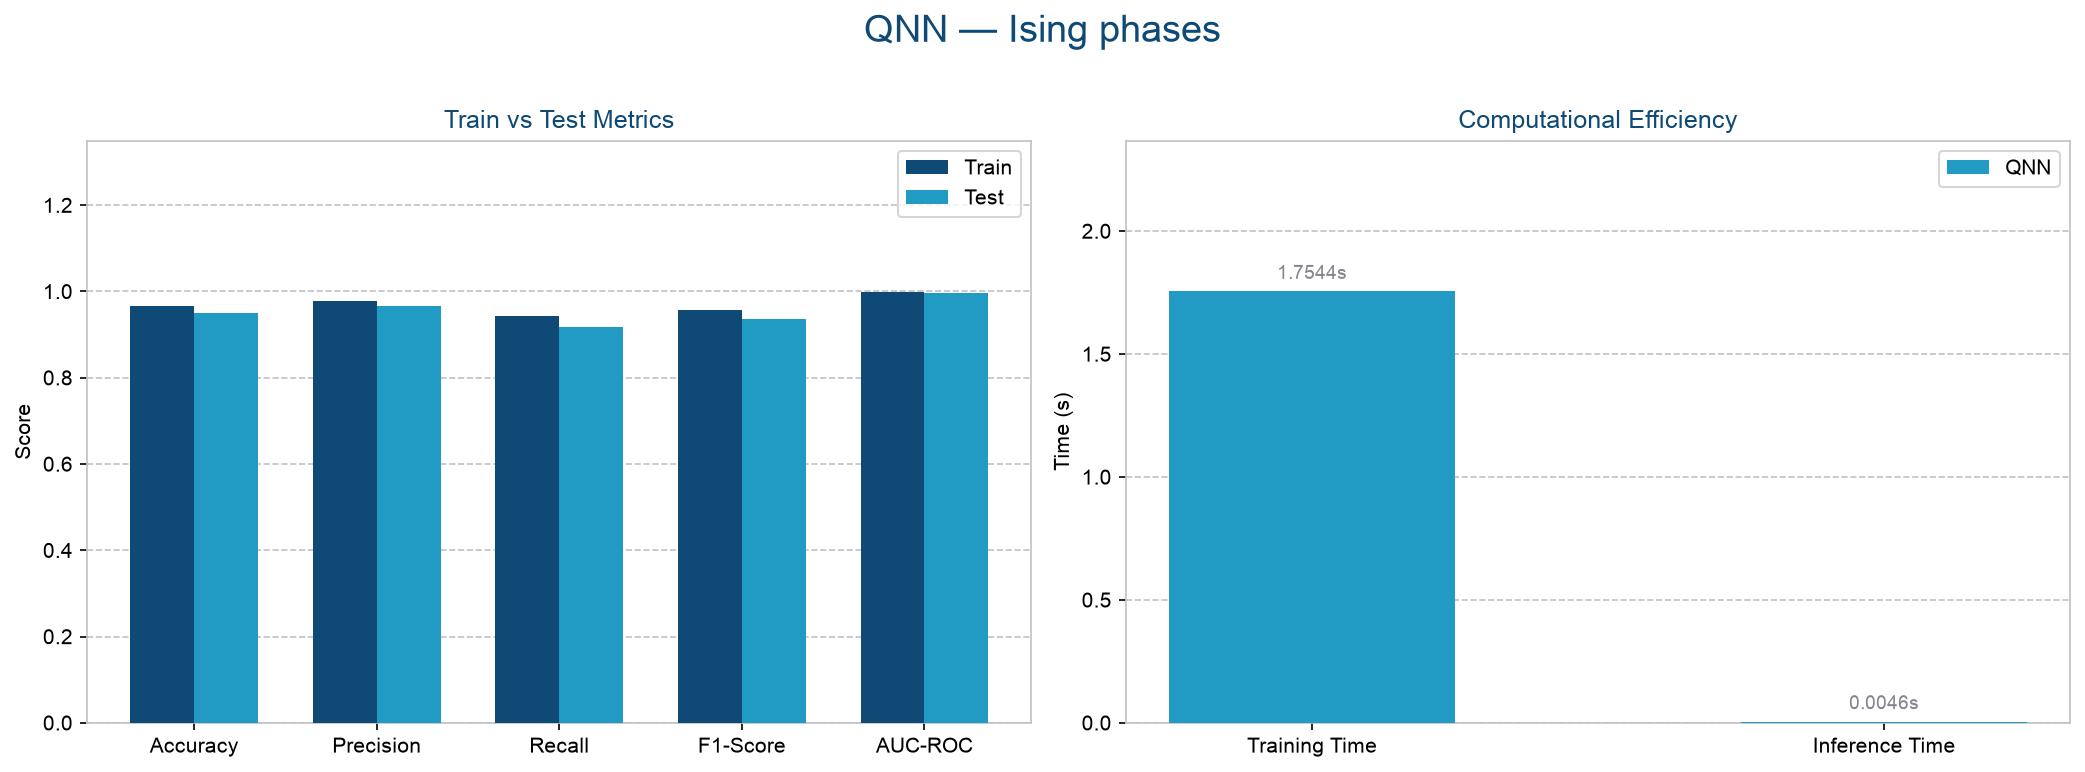

In [7]:
plt.rcParams.update({"font.sans-serif": ["Arial"], "axes.edgecolor": "#C0C0C8", "grid.color": "#C0C0C8", "grid.linestyle": "--"})

@torch.no_grad()
def get_inference_time(model, data):
    start = time.time(); _ = model(data); return time.time() - start

qnn_inf_time = get_inference_time(qnn_model, X_test)
train_color, test_color, unir_gris = "#0E4A75", "#219BC3", "#858591"
fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle("QNN — Ising phases", fontsize=18, y=1.02, color="#0E4A75")
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]
train_vals = [qnn_acc_tr, qnn_prec_tr, qnn_rec_tr, qnn_f1_tr, qnn_auc_tr]
test_vals = [qnn_acc, qnn_prec, qnn_rec, qnn_f1, qnn_auc]
x = np.arange(len(metrics)); width = 0.35
for i in range(len(metrics)):
    axs[0].bar(x[i] - width/2, train_vals[i], width, color=train_color, label="Train" if i==0 else "", zorder=3)
    axs[0].bar(x[i] + width/2, test_vals[i], width, color=test_color, label="Test" if i==0 else "", zorder=3)
axs[0].set_ylabel("Score"); axs[0].set_title("Train vs Test Metrics", color="#0E4A75")
axs[0].set_xticks(x); axs[0].set_xticklabels(metrics); axs[0].set_ylim(0, 1.35)
axs[0].legend(loc="upper right"); axs[0].grid(axis="y", zorder=0)
eff = [qnn_time, qnn_inf_time]; x_eff = np.arange(2)
axs[1].bar(x_eff, eff, 0.5, color=test_color, label="QNN", zorder=3)
axs[1].set_xticks(x_eff); axs[1].set_xticklabels(["Training Time", "Inference Time"])
axs[1].set_ylabel("Time (s)"); axs[1].set_title("Computational Efficiency", color="#0E4A75")
mt = max(eff); axs[1].set_ylim(0, mt*1.35 if mt>0 else 1); axs[1].legend(loc="upper right"); axs[1].grid(axis="y", zorder=0)
for i in range(2):
    axs[1].text(x_eff[i], eff[i] + (mt*0.02 if mt>0 else 0.02), f"{eff[i]:.4f}s", ha="center", va="bottom", fontsize=9, color=unir_gris)
plt.tight_layout(); plt.show()


## Guardar resultados


In [8]:
# Save metrics for IsingClassification comparison
# METRICS_PATH_OK: case_paths (no uses quantum/classical vars)
import json
from pathlib import Path
import sys

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "case_paths.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/case_paths.py not found")

import importlib
import case_paths as _case_paths
importlib.reload(_case_paths)
from case_paths import resolve_metrics_dir as _resolve_metrics_dir

def resolve_metrics_dir() -> Path:
    """Guarda en Notebooks/Classification/IsingClassification/metrics (helper compartido)."""
    return _resolve_metrics_dir("Classification", "IsingClassification")

metrics_dir = resolve_metrics_dir()



payload = {
    "model": "QNN",
    "family": "quantum",
    "protocol": {
        "dataset": "qspin-ising",
        "layouts": ["open/chain/1x4", "closed/chain/1x4"],
        "features": "ground_state Re||Im (32) -> PCA(4)",
        "label_rule": "y=(h > |J|) with J=-1 (1D TFIM critical field)",
        "n_features": int(n_features),
        "n_qubits": 4,
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
        "pca": "PCA(n_components=4)",
    },
    "train": {
        "accuracy": float(qnn_acc_tr),
        "precision": float(qnn_prec_tr),
        "recall": float(qnn_rec_tr),
        "f1": float(qnn_f1_tr),
        "auc": float(qnn_auc_tr),
    },
    "test": {
        "accuracy": float(qnn_acc),
        "precision": float(qnn_prec),
        "recall": float(qnn_rec),
        "f1": float(qnn_f1),
        "auc": float(qnn_auc),
    },
    "train_time_s": float(qnn_time),
    "inference_time_s": float(qnn_inf_time),
}

out = metrics_dir / "qnn_ising.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/metrics/qnn_ising.json


## Storytelling plots

`figures/`: PCA sin frontera + con frontera del **mismo** modelo ya entrenado.
Puntos test usan `*_preds` del notebook; la malla usa `modelo.predict` (sin reentrenar).


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/qnn_ising_chain.png


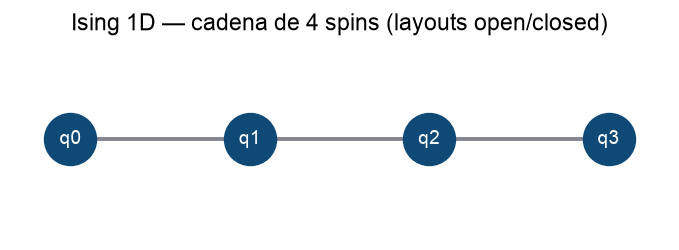

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/qnn_ising_z_profiles.png


/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/lib/storytelling.py:74: UserWarning: Glyph 10216 (\N{MATHEMATICAL LEFT ANGLE BRACKET}) missing from font(s) Arial.
  fig.savefig(path, bbox_inches="tight", facecolor="white", dpi=150)
/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/lib/storytelling.py:74: UserWarning: Glyph 10217 (\N{MATHEMATICAL RIGHT ANGLE BRACKET}) missing from font(s) Arial.
  fig.savefig(path, bbox_inches="tight", facecolor="white", dpi=150)
/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10216 (\N{MATHEMATICAL LEFT ANGLE BRACKET}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10217 (\N{MATHEMATICAL RIGHT ANGLE BRACKE

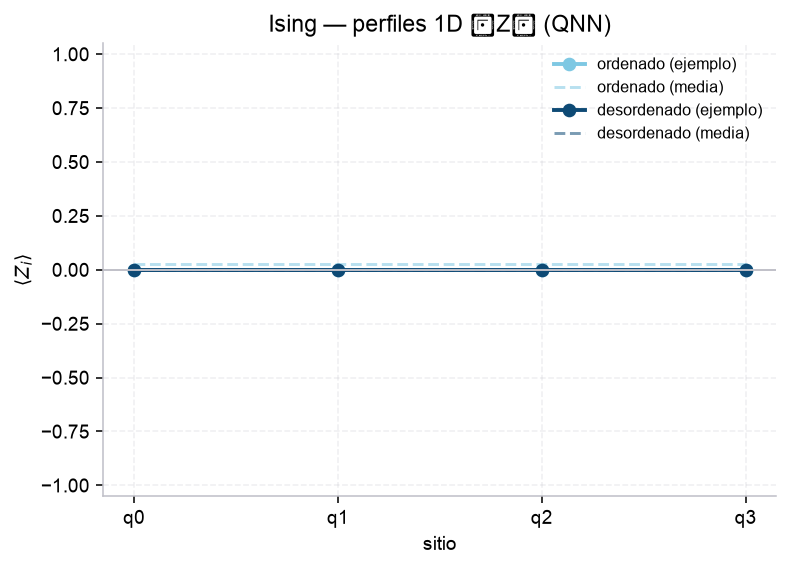

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/qnn_ising_M_vs_h.png


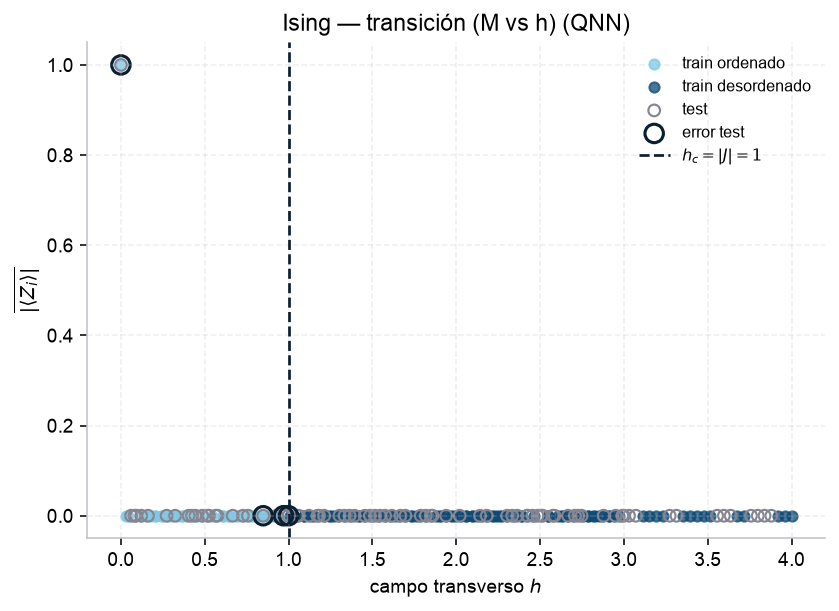

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/qnn_ising_pca_scatter.png


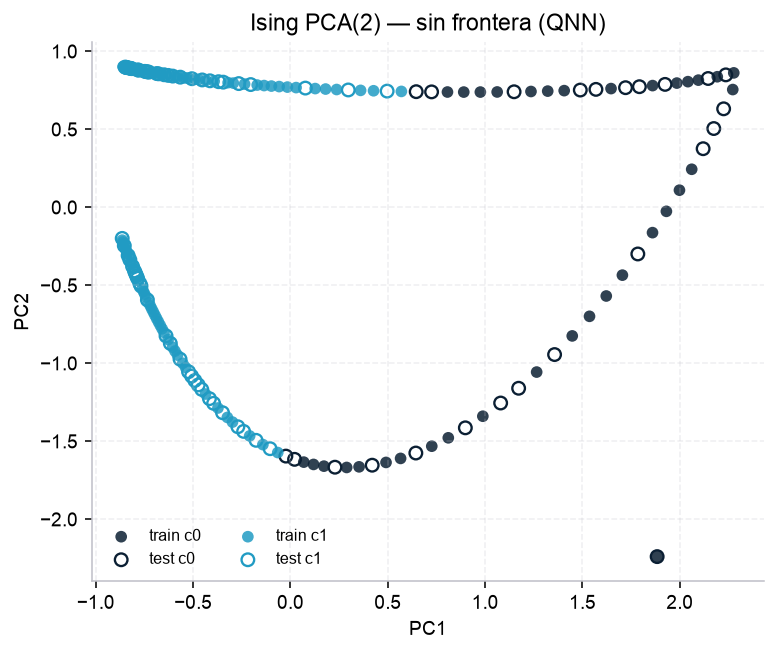

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/qnn_ising_pca_boundary.png


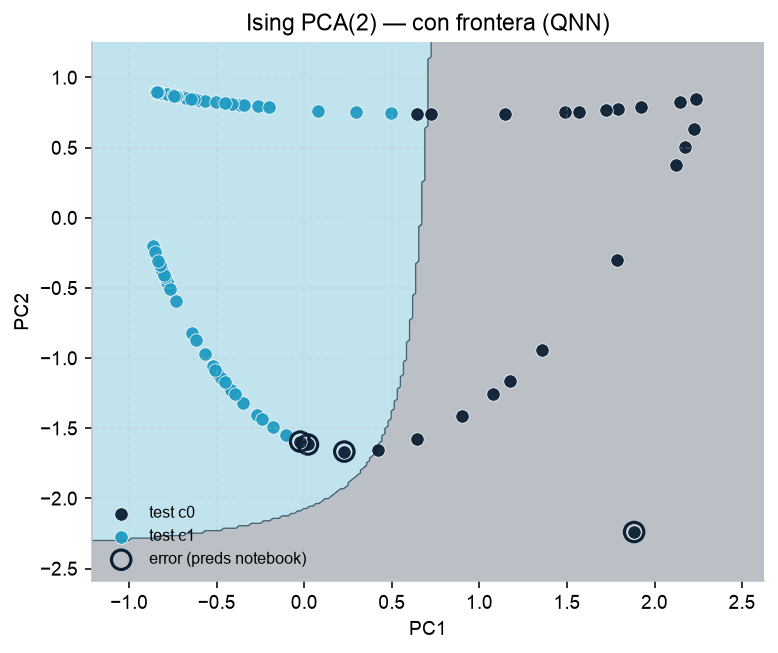

In [9]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import resolve_figures_dir, plot_ising_story

figures_dir = resolve_figures_dir("Classification", "IsingClassification")
def _predict_fn(X):
    import torch
    qnn_model.eval()
    xt = torch.as_tensor(np.asarray(X, dtype=np.float32))
    with torch.no_grad():
        return torch.argmax(qnn_model(xt), dim=1).cpu().numpy()
predict_fn = _predict_fn
_raw = X_train_raw if "X_train_raw" in globals() else X_train
plot_ising_story(
    _raw, y_train,
    h_train=h_train if "h_train" in globals() else None,
    h_test=h_test if "h_test" in globals() else None,
    X_test_raw=X_test_raw if "X_test_raw" in globals() else None,
    figures_dir=figures_dir,
    stem="qnn",
    title_model="QNN",
    X_train=X_train,
    X_test=X_test,
    y_test=y_test,
    y_pred_test=qnn_preds,
    predict_fn=predict_fn,
)

plt.show()
